# Diagnóstico de Diabetes — Tech Challenge Fase 1

O objetivo principal deste estudo é a classificação preditiva de pacientes diabéticos vs. não diabéticos utilizando algoritmos de Machine Learning. No entanto, a trajetória do projeto passou por um processo rigoroso de validação de viabilidade de dados (data audit), o que motivou uma alteração fundamentada na escolha da base de dados.

Inicialmente, o grupo explorou um dataset público focado em diagnóstico e estadiamento do câncer de próstata. Contudo, após uma análise exploratória minuciosa e testes preliminares de modelagem, o dataset foi descartado devido a severas inconsistências conceituais, estatísticas e clínicas:

1. Inconsistências Clínicas e Dados Impossíveis:
A base apresentou falhas graves de integridade e lógica médica, indicando ter sido gerada artificialmente (dados sintéticos gerados ao acaso). Exemplos críticos incluem:
* Estadiamento em pacientes benignos: Registros indicaram $1.926$ pacientes com biópsia benigna classificados com Cancer_Stage = Metastatic e $13.770$ pacientes benignos registrados com Cancer_Stage = Localized. Clinicamente, um paciente sem diagnóstico de neoplasia maligna não possui estadiamento tumoral.
* Anomalias Temporais de Idade: Foram identificados $9.420$ pacientes cuja idade no rastreamento (Screening_Age) era estritamente maior que a idade atual (Age), o que é temporal e logicamente impossível.
2. Ausência de Separabilidade e Padrão Clínico:
* Na prática médica, marcadores como o Antígeno Específico da Próstata (PSA) e alterações no toque retal apresentam forte correlação com o risco de malignidade. Na base analisada, contudo, a distribuição dessas variáveis era idêntica entre casos benignos e malignos, demonstrando total ausência de sinal estatístico real.

Diante da inviabilidade de extrair conhecimento útil ou generalizável da base de câncer de próstata, o grupo optou por migrar para o dataset público CDC BRFSS 2015 (Behavioral Risk Factor Surveillance System), disponibilizado pelo CDC via Kaggle, que apresenta sinal estatístico claro entre as classe
Classificação de pacientes **diabéticos vs. não diabéticos** usando Machine Learning,
a partir do dataset público **CDC BRFSS 2015** (Diabetes Health Indicators, via Kaggle).

In [1]:
import sys
from pathlib import Path

In [2]:
if "google.colab" in sys.modules:

  # evita pedir o upload de novo, caso necessite carregar o arquivo novamente remova o 'not' e execute a célula
  if not Path("/content/src/config.py").exists():
    import zipfile
    from google.colab import files
    enviados = files.upload()                      # escolha o arquivo zipado
    zipfile.ZipFile(next(iter(enviados))).extractall("/content")
  else:
    print("Arquivo já carregado!!")

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, classification_report,
                             ConfusionMatrixDisplay)
from xgboost import XGBClassifier
import shap

# Permite importar o pacote src/ a partir da pasta notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.config import (RANDOM_STATE, CAMINHO_CSV, PASTA_FIGURAS,
                        BINARIAS, ORDINAIS, CONTINUAS, FEATURES)

PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)
print("Dataset:", CAMINHO_CSV.relative_to(RAIZ))
print("Figuras:", PASTA_FIGURAS.relative_to(RAIZ))

Dataset: data/diabetes_012_health_indicators_BRFSS2015.csv
Figuras: reports/figures


# 2. Carga e exploração dos dados

## 2.1 Carregar o CSV

In [4]:
df = pd.read_csv(CAMINHO_CSV)

print("Dimensões:", df.shape)
df.head()

Dimensões: (253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## 2.2 Dicionário de dados

Fonte: CDC BRFSS 2015 (via Kaggle — "Diabetes Health Indicators Dataset").

| Coluna | Tipo | Significado |
|---|---|---|
| `Diabetes_012` | **alvo** | 0 = não diabético · 1 = pré-diabético · 2 = diabético |
| `HighBP` | binária (0/1) | Pressão alta |
| `HighChol` | binária (0/1) | Colesterol alto |
| `CholCheck` | binária (0/1) | Fez exame de colesterol nos últimos 5 anos |
| `BMI` | contínua | Índice de Massa Corporal |
| `Smoker` | binária (0/1) | Fumou 100+ cigarros na vida |
| `Stroke` | binária (0/1) | Já teve AVC (derrame) |
| `HeartDiseaseorAttack` | binária (0/1) | Doença cardíaca ou infarto |
| `PhysActivity` | binária (0/1) | Fez atividade física nos últimos 30 dias |
| `Fruits` | binária (0/1) | Consome fruta ao menos 1x/dia |
| `Veggies` | binária (0/1) | Consome vegetais ao menos 1x/dia |
| `HvyAlcoholConsump` | binária (0/1) | Consumo pesado de álcool |
| `AnyHealthcare` | binária (0/1) | Tem plano de saúde |
| `NoDocbcCost` | binária (0/1) | Deixou de ir ao médico por custo no último ano |
| `GenHlth` | ordinal (1–5) | Saúde geral autoavaliada (1 = excelente … 5 = ruim) |
| `MentHlth` | contagem (0–30) | Dias no último mês com saúde mental ruim |
| `PhysHlth` | contagem (0–30) | Dias no último mês com saúde física ruim |
| `DiffWalk` | binária (0/1) | Dificuldade para caminhar |
| `Sex` | binária (0/1) | 0 = feminino, 1 = masculino |
| `Age` | ordinal (1–13) | Faixa etária (1 = 18–24 … 13 = 80+) |
| `Education` | ordinal (1–6) | Escolaridade |
| `Income` | ordinal (1–8) | Renda |

## 2.3 Tipos das variáveis

As 21 features foram classificadas em três grupos (definidos em `src/config.py`) e convertidas para inteiros:

| Grupo | Colunas | Tratamento |
|---|---|---|
| Binárias | 14 colunas 0/1 | Mantidas como estão |
| Ordinais | GenHlth, Age, Education, Income | Mantidas como inteiros e padronizadas |
| Contínuas/contagem | BMI, MentHlth, PhysHlth | Padronizadas |

In [5]:
# Conferência: nenhuma coluna ficou de fora dos grupos
assert set(FEATURES) == set(df.columns) - {"Diabetes_012"}

df[BINARIAS + ORDINAIS + ["Diabetes_012"]] = df[BINARIAS + ORDINAIS + ["Diabetes_012"]].astype("int8")
df[CONTINUAS] = df[CONTINUAS].astype("int16")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   Diabetes_012          253680 non-null  int8 
 1   HighBP                253680 non-null  int8 
 2   HighChol              253680 non-null  int8 
 3   CholCheck             253680 non-null  int8 
 4   BMI                   253680 non-null  int16
 5   Smoker                253680 non-null  int8 
 6   Stroke                253680 non-null  int8 
 7   HeartDiseaseorAttack  253680 non-null  int8 
 8   PhysActivity          253680 non-null  int8 
 9   Fruits                253680 non-null  int8 
 10  Veggies               253680 non-null  int8 
 11  HvyAlcoholConsump     253680 non-null  int8 
 12  AnyHealthcare         253680 non-null  int8 
 13  NoDocbcCost           253680 non-null  int8 
 14  GenHlth               253680 non-null  int8 
 15  MentHlth              253680 non-n

As variáveis foram classificadas em binárias, ordinais e contínuas. As ordinais foram mantidas como inteiros, e não codificadas em one-hot, porque possuem ordem natural que o modelo deve aproveitar.

## 2.4 Valores ausentes

In [6]:
df.isnull().sum().sum()  # total de valores ausentes na base

np.int64(0)

Não há valores ausentes em nenhuma coluna, portanto não é necessária imputação.

## 2.5 Estatísticas descritivas

`describe()` calcula contagem, média, desvio padrão, mínimo, quartis e máximo de cada coluna.

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Diabetes_012,253680.0,0.296921,0.698160,0.0,0.0,0.0,0.0,2.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


Observações:

- **IMC máximo de 98.** Pela classificação da OMS, o IMC normal vai de 18,5 a 24,9; de 25 a 29,9 é sobrepeso; a partir de 30 é obesidade, e acima de 40, obesidade grave. Valores acima de 60 são raríssimos e provavelmente podem ser considerados um erro de registro. O tratamento é feito na seção 4.
- **Categorias codificadas como números.** Age (1–13) representa faixas etárias, não anos. GenHlth (1–5), Education (1–6) e Income (1–8) são níveis ordinais. As binárias são 0 = não, 1 = sim; por isso a média de HighBP (0,43) indica que 43% das pessoas têm pressão alta.
- **Alvo com 3 classes.** Diabetes_012 assume 0, 1 e 2. Na seção 3 ele é convertido para binário.

## 2.6 Distribuição do alvo

In [8]:
dist = df["Diabetes_012"].value_counts(normalize=True).sort_index() * 100
print("Distribuição da variável alvo (em %):")
print(dist.round(2))

Distribuição da variável alvo (em %):
Diabetes_012
0    84.24
1     1.83
2    13.93
Name: proportion, dtype: float64


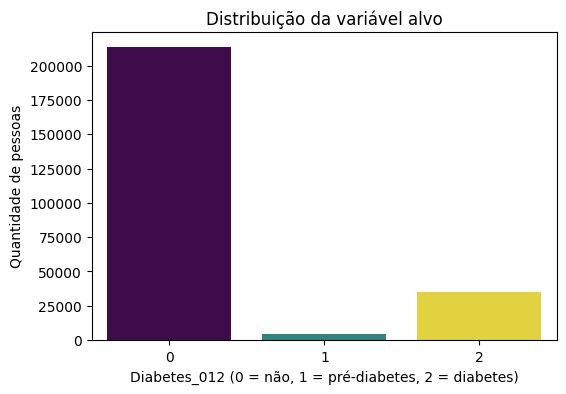

In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(x="Diabetes_012", hue="Diabetes_012", data=df, palette="viridis", legend=False)
plt.title("Distribuição da variável alvo")
plt.xlabel("Diabetes_012 (0 = não, 1 = pré-diabetes, 2 = diabetes)")
plt.ylabel("Quantidade de pessoas")
plt.savefig(PASTA_FIGURAS / "distribuicao_alvo.png", dpi=120, bbox_inches="tight")
plt.show()

84% das pessoas não têm diabetes. Um modelo que sempre respondesse "não diabético", sem olhar nenhuma variável, acertaria 84% dos casos e não detectaria nenhum doente.

Esse é o problema do **desbalanceamento de classes**: a classe majoritária domina a base e torna a acurácia uma métrica enganosa. Por isso as métricas principais deste trabalho são o **recall** (proporção de diabéticos encontrados) e o **PR-AUC**.

## 2.7 As features diferem entre os grupos?

A média de cada feature por classe mostra se a base tem sinal estatístico para o modelo aprender.

In [10]:
df.groupby("Diabetes_012").mean().T.round(3)

Diabetes_012,0,1,2
HighBP,0.371,0.629,0.753
HighChol,0.379,0.621,0.670
CholCheck,0.957,0.987,0.993
BMI,27.743,30.724,31.944
Smoker,0.430,0.493,0.518
Stroke,0.032,0.057,0.092
HeartDiseaseorAttack,0.072,0.143,0.223
PhysActivity,0.779,0.678,0.631
Fruits,0.643,0.602,0.585
Veggies,0.821,0.769,0.756


A classe de pré-diabetes (1) fica sempre entre as outras duas (por exemplo, IMC médio de 27,7 → 30,7 → 31,9). Ela é uma zona intermediária entre "saudável" e "diabético", difícil de separar, e representa apenas 1,8% da base.

# 3. Definição do alvo binário

In [11]:
# Diabético (2) -> 1 ; não diabético (0) e pré-diabético (1) -> 0
df["Diabetes_binary"] = (df["Diabetes_012"] == 2).astype("int8")

print("Distribuição do alvo binário (em %):")
print((df["Diabetes_binary"].value_counts(normalize=True) * 100).round(2))

Distribuição do alvo binário (em %):
Diabetes_binary
0    86.07
1    13.93
Name: proportion, dtype: float64


**Decisão:** agrupamos a pré-diabetes com os não diabéticos porque o objetivo é apoiar o diagnóstico da doença instalada. Testamos a alternativa (pré-diabetes como positivo) e o desempenho foi equivalente. Como a pré-diabetes representa só 1,8% da base, o impacto da escolha é limitado.

**Valores a serem considerados no modelo**

Diabéticos = 1;
Não-diabéticos = 0

## 3.1 Distribuições por classe

Os gráficos usam `stat="percent", common_norm=False`: cada classe é normalizada separadamente. Sem isso, as barras dos diabéticos ficariam cerca de 6 vezes menores apenas porque eles são 6 vezes menos numerosos.

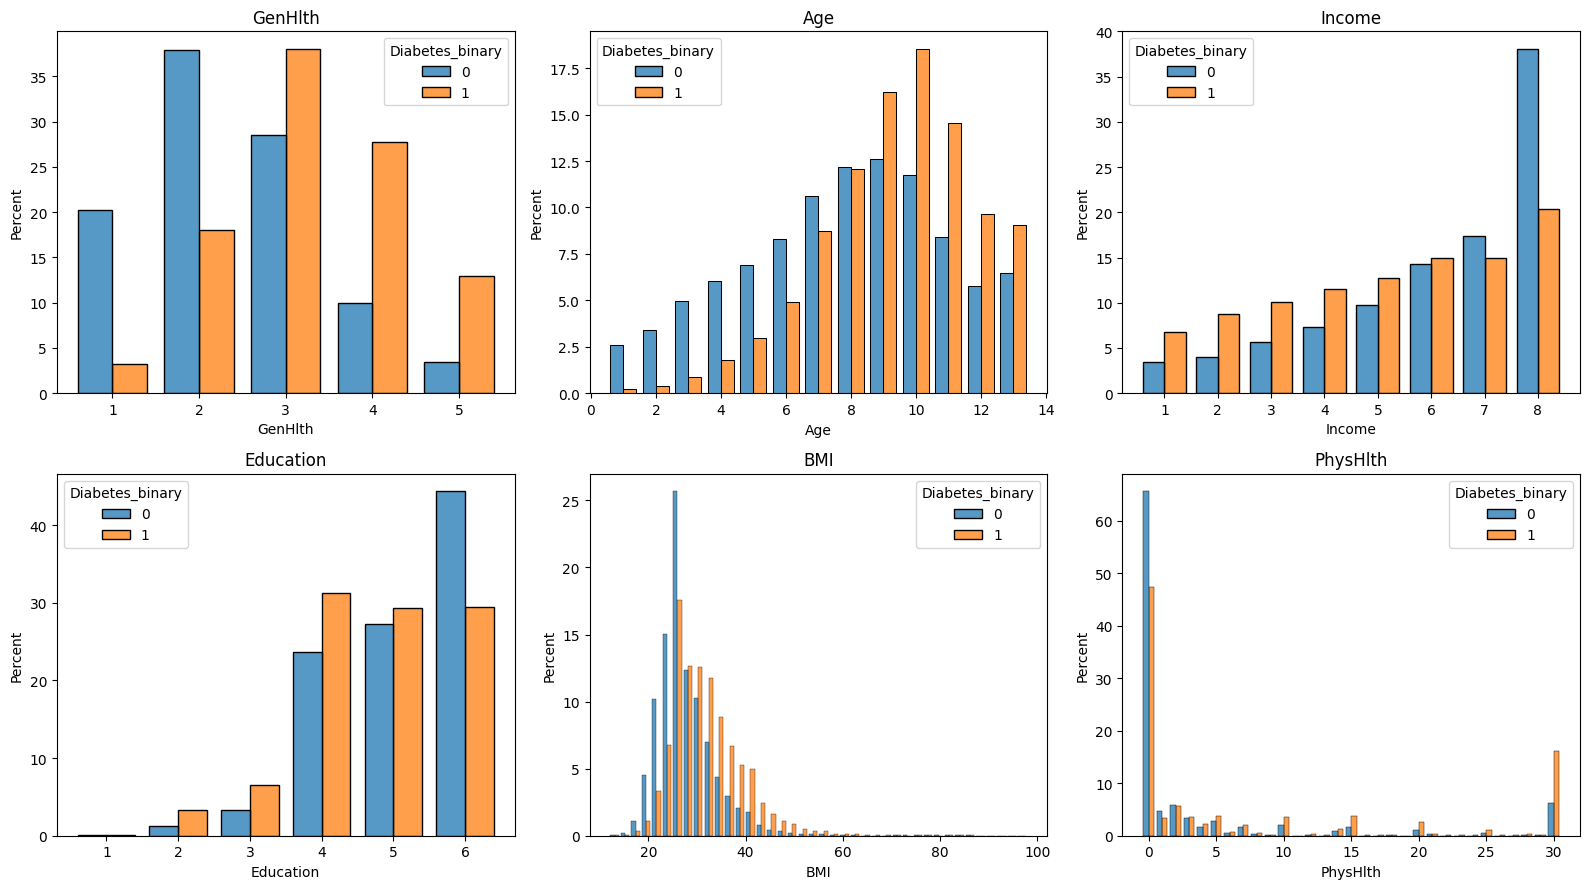

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, ["GenHlth", "Age", "Income", "Education", "BMI", "PhysHlth"]):
    sns.histplot(data=df, x=col, hue="Diabetes_binary", stat="percent", common_norm=False,
                 discrete=(col != "BMI"), bins=(40 if col == "BMI" else "auto"),
                 multiple="dodge", shrink=0.8, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "distribuicoes_por_classe.png", dpi=120)
plt.show()

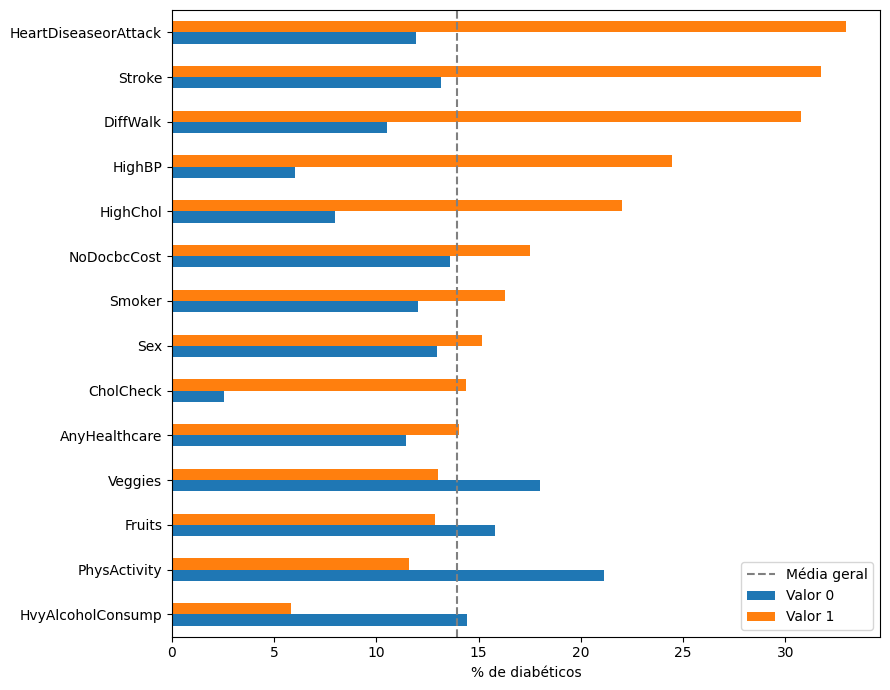

In [13]:
taxa = pd.DataFrame({c: df.groupby(c)["Diabetes_binary"].mean() * 100 for c in BINARIAS}).T
taxa.columns = ["Valor 0", "Valor 1"]

ax = taxa.sort_values("Valor 1").plot.barh(figsize=(9, 7))
ax.axvline(df["Diabetes_binary"].mean() * 100, color="gray", linestyle="--", label="Média geral")
ax.set_xlabel("% de diabéticos")
ax.legend()
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "taxa_binarias.png", dpi=120)
plt.show()

Análise gráfica:

- **GenHlth:** a maioria dos não diabéticos se avalia como 1 ou 2 (excelente/muito boa); entre os diabéticos, o pico está em 3, e cerca de 41% estão em 4 ou 5.
- **Age:** a distribuição dos diabéticos é deslocada para faixas mais velhas, com pico na faixa 10 (65–69 anos).
- **Income:** a renda mais alta (8) concentra 38% dos não diabéticos e apenas 20% dos diabéticos.
- **BMI:** a curva dos diabéticos é deslocada para a direita, com concentração acima de 30 (obesidade).
- **PhysHlth:** as respostas se acumulam em 0 e 30, padrão típico de dado autorrelatado, em que o entrevistado arredonda para "nenhum dia" ou "o mês todo".
- **Binárias:** entre quem tem doença cardíaca, 33% são diabéticos (contra 12% sem); com pressão alta, 24% (contra 6%).
- **CholCheck e HvyAlcoholConsump:** entre quem não fez exame de colesterol, só 2,5% são diabéticos. Isso não indica proteção, e sim falta de diagnóstico: quem não vai ao médico não descobre a doença. O consumo pesado de álcool aparece associado a menos diabetes provavelmente porque quem já tem o diagnóstico reduz o consumo.

As associações confirmam os fatores de risco conhecidos, mas não implicam causalidade.

## 3.2 IMC por classe

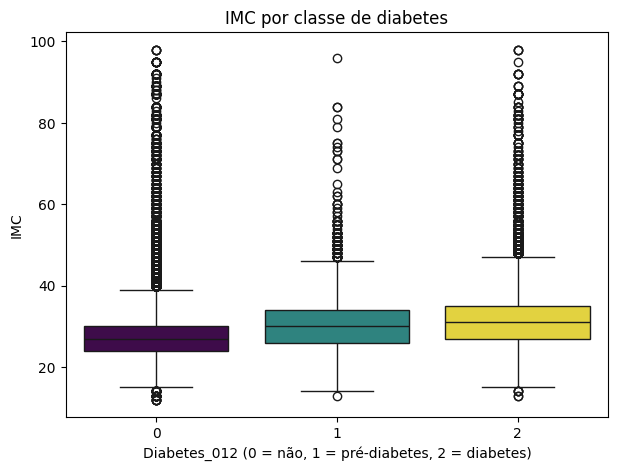

In [14]:
plt.figure(figsize=(7, 5))
sns.boxplot(x="Diabetes_012", y="BMI", hue="Diabetes_012", data=df, palette="viridis", legend=False)
plt.title("IMC por classe de diabetes")
plt.xlabel("Diabetes_012 (0 = não, 1 = pré-diabetes, 2 = diabetes)")
plt.ylabel("IMC")
plt.savefig(PASTA_FIGURAS / "imc_por_classe.png", dpi=120, bbox_inches="tight")
plt.show()

# 4. Limpeza dos dados

Duas operações de limpeza, cada uma com sua justificativa: remoção de duplicatas e tratamento do outlier de IMC.

## 4.1 Duplicatas

In [15]:
duplicadas = df.duplicated()
print(f"Linhas duplicadas: {duplicadas.sum()}")
print(f"% de diabéticos entre as duplicadas: {df.loc[duplicadas, 'Diabetes_binary'].mean():.1%}")
print(f"Prevalência antes: {df['Diabetes_binary'].mean():.1%}")

df = df.drop_duplicates().reset_index(drop=True)

print(f"Prevalência depois: {df['Diabetes_binary'].mean():.1%}  |  Linhas: {len(df)}")

Linhas duplicadas: 23899
% de diabéticos entre as duplicadas: 1.0%
Prevalência antes: 13.9%
Prevalência depois: 15.3%  |  Linhas: 229781


As duplicatas são quase todas de não diabéticos sem fatores de risco (só 1,0% de diabéticos). Como as features são majoritariamente binárias, pessoas **diferentes** podem gerar linhas idênticas.

Optamos por removê-las para evitar que a mesma linha apareça no treino e no teste, o que inflaria a avaliação. Em contrapartida, a prevalência sobe de 13,9% para 15,3%, o que deixa a precisão do modelo levemente otimista.

## 4.2 Outlier de IMC

In [16]:
print(f"Valores de BMI > 60 antes: {(df['BMI'] > 60).sum()}")

df["BMI"] = df["BMI"].clip(upper=60)   # todo valor acima de 60 vira 60

print(f"Valores de BMI > 60 depois: {(df['BMI'] > 60).sum()}")
print(f"BMI máximo agora: {df['BMI'].max()}")

Valores de BMI > 60 antes: 805
Valores de BMI > 60 depois: 0
BMI máximo agora: 60


Valores de IMC acima de 60 foram limitados a 60 com `.clip(upper=60)` (winsorização). Pela classificação da OMS, IMC acima de 40 já caracteriza obesidade grave, e valores acima de 60 são considerados valores extremos e podem indicar erro de registro na maioria dos casos. Limitar, em vez de excluir, preserva as demais informações dessas 805 pessoas.

# 5. Análise de correlação

A correlação mede a força da relação entre duas variáveis, de −1 (relação inversa) a +1 (relação direta); 0 indica ausência de relação.

Usamos a correlação de **Spearman**, que trabalha com a ordem dos valores e é adequada a variáveis binárias e ordinais, que formam a maior parte desta base. A análise é feita depois da limpeza, sobre os mesmos dados que o modelo vai usar.

## 5.1 Matriz de correlação

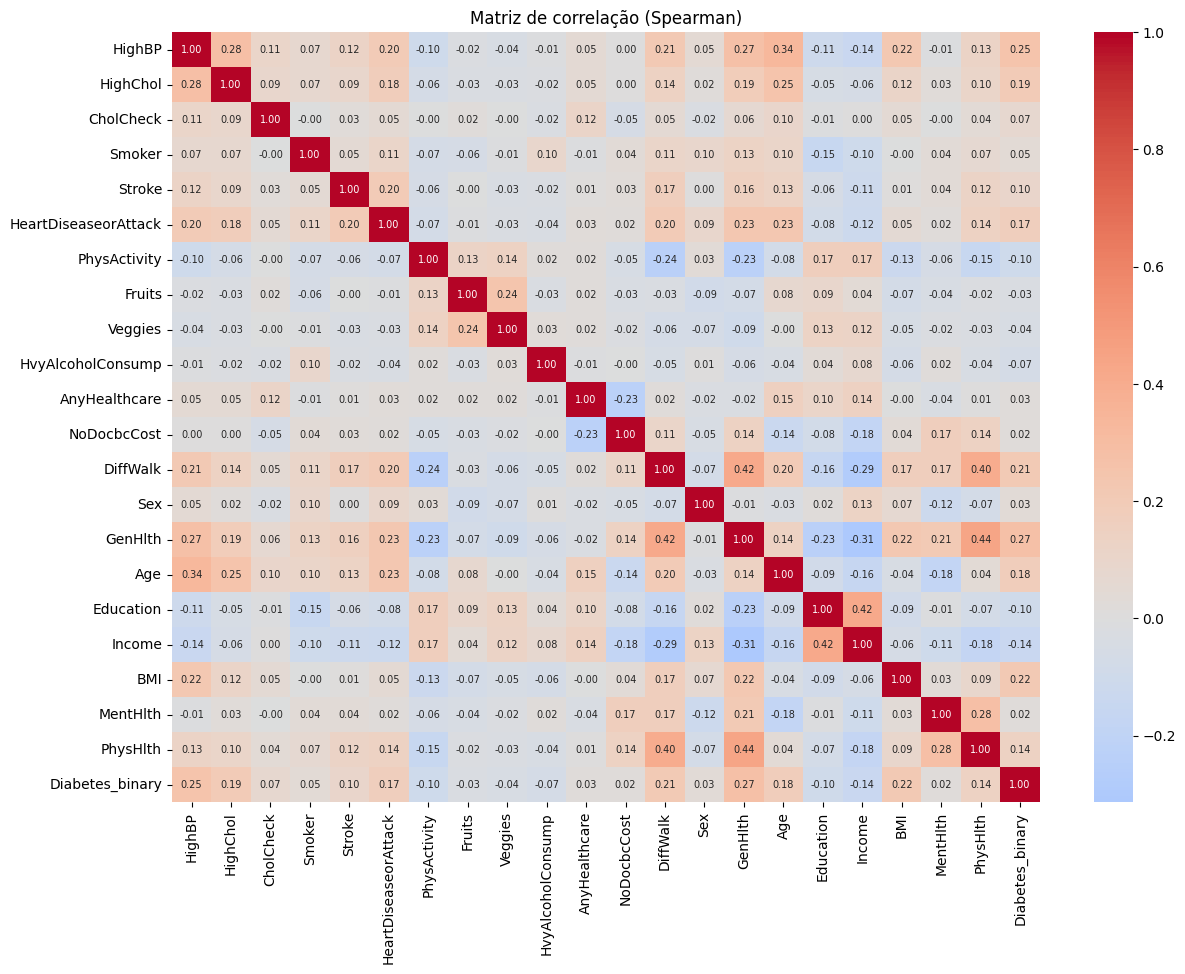

In [17]:
plt.figure(figsize=(14, 10))
corr = df[FEATURES + ["Diabetes_binary"]].corr(method="spearman")
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Matriz de correlação (Spearman)")
plt.savefig(PASTA_FIGURAS / "matriz_correlacao.png", dpi=120, bbox_inches="tight")
plt.show()

## 5.2 Correlação com o alvo e entre features

In [18]:
# Correlação com o alvo binário: Pearson e Spearman lado a lado
corr_alvo = pd.DataFrame({
    "pearson": df[FEATURES].corrwith(df["Diabetes_binary"]),
    "spearman": df[FEATURES].corrwith(df["Diabetes_binary"], method="spearman"),
}).sort_values("spearman", ascending=False)
print(corr_alvo.round(3))

# Pares de features mais correlacionados entre si (multicolinearidade)
matriz = df[FEATURES].corr(method="spearman").abs()
superior = matriz.where(np.triu(np.ones(matriz.shape), k=1).astype(bool))
print(superior.stack().sort_values(ascending=False).head(5).round(3))

                      pearson  spearman
GenHlth                 0.277     0.273
HighBP                  0.254     0.254
BMI                     0.216     0.218
DiffWalk                0.206     0.206
HighChol                0.195     0.195
Age                     0.177     0.175
HeartDiseaseorAttack    0.168     0.168
PhysHlth                0.156     0.137
Stroke                  0.099     0.099
CholCheck               0.072     0.072
Smoker                  0.046     0.046
Sex                     0.033     0.033
AnyHealthcare           0.025     0.025
NoDocbcCost             0.020     0.020
MentHlth                0.054     0.019
Fruits                 -0.025    -0.025
Veggies                -0.042    -0.042
HvyAlcoholConsump      -0.066    -0.066
Education              -0.103    -0.098
PhysActivity           -0.101    -0.101
Income                 -0.141    -0.139


GenHlth    PhysHlth    0.439
DiffWalk   GenHlth     0.419
Education  Income      0.417
DiffWalk   PhysHlth    0.405
HighBP     Age         0.336
dtype: float64


Usamos a correlação de Spearman por ser adequada a variáveis binárias e ordinais. As correlações com o alvo são moderadas (máximo 0,27), o que é esperado para uma doença multifatorial. O maior par entre features (0,44) está bem abaixo de níveis que indicariam multicolinearidade.

As features mais correlacionadas com o alvo são positivas e têm sentido clínico: saúde geral ruim (GenHlth), pressão alta, IMC, dificuldade de caminhar, colesterol alto e idade. As correlações negativas também são coerentes: atividade física, escolaridade e renda mais altas se associam a menos diabetes.

Nenhuma correlação com o alvo é alta. Isso é esperado em uma doença multifatorial; uma correlação próxima de 0,9 seria sinal de vazamento de informação.

**Correlação não é causalidade.** GenHlth alto se associa ao diabetes, mas sentir-se mal não causa diabetes; é mais provável que a doença piore a saúde geral.

# 6. Separação treino / validação / teste

| Conjunto | Uso | O modelo aprende com ele? |
|---|---|---|
| **Treino (70%)** | Ajuste dos modelos | Sim |
| **Validação (15%)** | Comparação de modelos e escolha do limiar | Não |
| **Teste (15%)** | Avaliação final, usada uma única vez | Não |


In [19]:
X = df[FEATURES]
y = df["Diabetes_binary"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

for nome, alvo in [("Treino", y_train), ("Validação", y_val), ("Teste", y_test)]:
    print(f"{nome:10s} {len(alvo):>7d} linhas | {alvo.mean():.1%} diabéticos")

Treino      160846 linhas | 15.3% diabéticos
Validação    34467 linhas | 15.3% diabéticos
Teste        34468 linhas | 15.3% diabéticos


- `stratify=y` garante a mesma proporção de diabéticos (15,3%) nos três conjuntos, como mostra a saída acima.
- `random_state=RANDOM_STATE` fixa o sorteio, garantindo a reprodutibilidade.

## 6.1 Pipeline de pré-processamento

In [20]:
preprocessador = ColumnTransformer([
    ("escala", StandardScaler(), CONTINUAS + ORDINAIS),
    ("binarias", "passthrough", BINARIAS),
])

O `ColumnTransformer` aplica um tratamento por grupo de variáveis: padroniza contínuas e ordinais (média 0, desvio padrão 1) e mantém as binárias como estão (`passthrough`).

O pré-processamento é encapsulado em um `Pipeline` junto com o modelo. Assim, o escalonamento é ajustado apenas nos dados de treino, inclusive dentro de cada dobra da validação cruzada, o que elimina o risco de vazamento de dados.

A padronização é necessária para a Regressão Logística, sensível à escala das variáveis (o IMC vai de 12 a 60, enquanto Age vai de 1 a 13). Modelos de árvore (Random Forest e XGBoost) não precisam dela, porque só fazem comparações do tipo "IMC > 30?"; por isso apenas a Regressão Logística recebe o `preprocessador`.

# 7. Treinamento e comparação dos modelos

São comparadas três famílias de modelos (linear, bagging de árvores e boosting de árvores) contra um baseline que sempre prevê a classe majoritária.

Para compensar o desbalanceamento, os modelos dão peso maior aos erros na classe rara: `class_weight="balanced"` na Regressão Logística e na Random Forest, e `scale_pos_weight` (razão entre negativos e positivos no treino) no XGBoost.

In [21]:
peso_positivos = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {peso_positivos:.2f}")

modelos = {
    "Baseline (sempre 'não')": Pipeline([
        ("modelo", DummyClassifier(strategy="most_frequent"))]),
    "Regressão Logística": Pipeline([
        ("prep", preprocessador),
        ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Random Forest": Pipeline([
        ("modelo", RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=20,
                                          class_weight="balanced", n_jobs=-1,
                                          random_state=RANDOM_STATE))]),
    "XGBoost": Pipeline([
        ("modelo", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5,
                                 scale_pos_weight=peso_positivos, eval_metric="logloss",
                                 n_jobs=-1, random_state=RANDOM_STATE))]),
}

resultados = []
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    proba = modelo.predict_proba(X_val)[:, 1]
    pred = modelo.predict(X_val)
    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_val, pred),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "Precisão": precision_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, proba),
        "PR-AUC": average_precision_score(y_val, proba),
    })

tabela_modelos = pd.DataFrame(resultados).set_index("Modelo").round(3)
tabela_modelos

scale_pos_weight = 5.55


,Acurácia,Recall,Precisão,F1,ROC-AUC,PR-AUC
Modelo,,,,,,
Baseline (sempre 'não'),0.847,0.000,0.000,0.000,0.500,0.153
Regressão Logística,0.720,0.764,0.323,0.454,0.814,0.426
Random Forest,0.717,0.778,0.323,0.457,0.818,0.439
XGBoost,0.713,0.790,0.321,0.457,0.820,0.443


Comparamos três famílias de modelos contra um baseline que sempre prevê a classe majoritária. O baseline atinge a maior acurácia (84,7%) sem detectar nenhum diabético, o que justifica o uso de recall e PR-AUC como métricas principais. Os três modelos têm desempenho próximo (ROC-AUC entre 0,81 e 0,82), indicando que o limite está na informação contida nos dados.

Com o peso nas classes, o recall no limiar padrão (0,5) fica entre 76% e 79%. O peso nas classes e o ajuste do limiar (seção 8) são duas formas de atingir o mesmo objetivo: priorizar a detecção dos diabéticos.

## 7.1 Ajuste de hiperparâmetros (XGBoost)

Busca aleatória de 15 combinações com validação cruzada estratificada de 3 dobras, otimizando o PR-AUC (`average_precision`). A busca usa apenas o conjunto de treino.

In [22]:
espaco = {
    "n_estimators": [200, 300, 500],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [3, 4, 5, 6],
    "min_child_weight": [1, 5, 10],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
}

busca = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=peso_positivos, eval_metric="logloss",
                  n_jobs=-1, random_state=RANDOM_STATE),
    param_distributions=espaco,
    n_iter=15,
    scoring="average_precision",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    verbose=1,
)
busca.fit(X_train, y_train)

print("Melhores parâmetros:", busca.best_params_)
print(f"PR-AUC médio na validação cruzada: {busca.best_score_:.4f}")

modelo_final = busca.best_estimator_
proba_val = modelo_final.predict_proba(X_val)[:, 1]
print(f"Validação — ROC-AUC: {roc_auc_score(y_val, proba_val):.4f} | "
      f"PR-AUC: {average_precision_score(y_val, proba_val):.4f}")

Fitting 3 folds for each of 15 candidates, totalling 45 fits


Melhores parâmetros: {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.85}
PR-AUC médio na validação cruzada: 0.4331
Validação — ROC-AUC: 0.8204 | PR-AUC: 0.4442


A busca de hiperparâmetros com validação cruzada estratificada não trouxe ganho relevante (PR-AUC 0,444 contra 0,443). Combinado com o empate entre os três algoritmos, isso indica que o desempenho está limitado pela informação disponível nos dados autorrelatados, e não pela escolha do modelo.

O modelo final é o XGBoost com os hiperparâmetros encontrados na busca (`modelo_final`).

# 8. Escolha do limiar de decisão

O modelo devolve um score entre 0 e 1. O `predict()` classifica como diabético quando o score é ≥ 0,5, mas esse valor é arbitrário e pode ser ajustado:

- **Limiar alto:** só sinaliza quando há muita certeza; gera poucos alarmes falsos, mas deixa passar mais doentes (recall baixo).
- **Limiar baixo:** sinaliza com menos certeza; encontra mais doentes (recall alto), mas gera mais alarmes falsos (precisão baixa).

O limiar é escolhido no conjunto de **validação**.

## 8.1 Curvas ROC e Precision-Recall

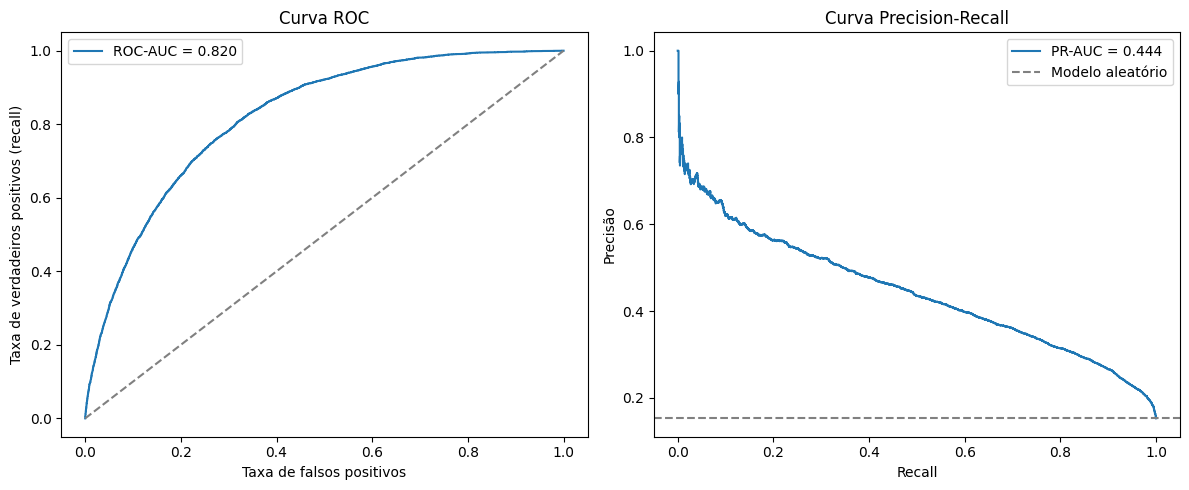

In [23]:
fpr, tpr, _ = roc_curve(y_val, proba_val)
prec_curva, rec_curva, _ = precision_recall_curve(y_val, proba_val)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y_val, proba_val):.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_xlabel("Taxa de falsos positivos")
axes[0].set_ylabel("Taxa de verdadeiros positivos (recall)")
axes[0].set_title("Curva ROC")
axes[0].legend()

axes[1].plot(rec_curva, prec_curva, label=f"PR-AUC = {average_precision_score(y_val, proba_val):.3f}")
axes[1].axhline(y_val.mean(), linestyle="--", color="gray", label="Modelo aleatório")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisão")
axes[1].set_title("Curva Precision-Recall")
axes[1].legend()

plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "curvas_roc_pr.png", dpi=120)
plt.show()

Cada ponto das curvas corresponde a um limiar. A curva Precision-Recall é a mais informativa para classes desbalanceadas: ela mostra a troca entre encontrar doentes (recall) e evitar alarmes falsos (precisão).

O PR-AUC do modelo é 0,44. Um modelo aleatório teria PR-AUC igual à prevalência (0,15, linha tracejada), ou seja, o modelo é cerca de 3 vezes melhor que o acaso.

## 8.2 Pontos de operação

In [24]:
precisao, recall, limiares = precision_recall_curve(y_val, proba_val)
precisao, recall = precisao[:-1], recall[:-1]   # o último ponto não tem limiar associado

opcoes = []
for alvo in [0.80, 0.85, 0.90]:
    i = np.where(recall >= alvo)[0][-1]   # maior limiar que ainda atinge o recall-alvo
    opcoes.append((f"Recall ≥ {alvo:.0%}", limiares[i], recall[i], precisao[i]))

f1 = 2 * precisao * recall / (precisao + recall + 1e-12)
i = f1.argmax()
opcoes.append(("Melhor F1", limiares[i], recall[i], precisao[i]))

pontos = pd.DataFrame(opcoes, columns=["Critério", "Limiar", "Recall", "Precisão"])
prevalencia = y_val.mean()
pontos["Diabéticos detectados /1000"] = (pontos["Recall"] * prevalencia * 1000).round()
pontos["Alarmes falsos /1000"] = (pontos["Diabéticos detectados /1000"]
                                  * (1 / pontos["Precisão"] - 1)).round()
pontos["Diabéticos perdidos /1000"] = (prevalencia * 1000
                                       - pontos["Diabéticos detectados /1000"]).round()
display(pontos.round(3))

LIMIAR = float(pontos.loc[pontos["Critério"] == "Recall ≥ 90%", "Limiar"].iloc[0])
print(f"Limiar escolhido: {LIMIAR:.3f}")

,Critério,Limiar,Recall,Precisão,Diabéticos detectados /1000,Alarmes falsos /1000,Diabéticos perdidos /1000
0,Recall ≥ 80%,0.489,0.800,0.314,122.0,266.0,31.0
1,Recall ≥ 85%,0.431,0.850,0.293,130.0,314.0,23.0
2,Recall ≥ 90%,0.357,0.900,0.266,137.0,378.0,16.0
3,Melhor F1,0.635,0.613,0.395,94.0,144.0,59.0


Limiar escolhido: 0.357


A tabela compara quatro limiares possíveis, traduzidos em pacientes a cada 1.000 atendidos:

- **Recall ≥ 80%, 85% e 90%:** o maior limiar que ainda atinge o recall desejado, o que garante a melhor precisão possível dentro do objetivo.
- **Melhor F1:** o ponto de equilíbrio entre precisão e recall.

Subir de 85% para 90% de recall encontra 7 diabéticos a mais a cada 1.000 pacientes, ao custo de 64 exames extras, cerca de 9 exames por diabético adicional.

Escolhemos o limiar de recall 90% porque o custo de um falso negativo (diabético sem diagnóstico) supera o de um falso positivo, que se resolve com um exame de glicemia. A tabela mostra que essa escolha gera cerca de 9 exames de confirmação para cada diabético adicional encontrado. Em contextos com exame confirmatório caro, o limiar de recall 85% seria preferível.

# 9. Avaliação final no conjunto de teste

O conjunto de teste é usado aqui pela primeira e única vez, com o modelo e o limiar definidos nas seções anteriores.

Limiar: 0.357
ROC-AUC: 0.8169 | PR-AUC: 0.4349

               precision    recall  f1-score   support

Não diabético       0.97      0.55      0.70     29203
    Diabético       0.26      0.90      0.41      5265

     accuracy                           0.60     34468
    macro avg       0.62      0.72      0.56     34468
 weighted avg       0.86      0.60      0.66     34468



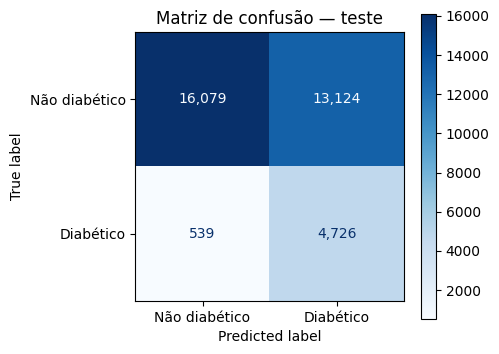

In [25]:
proba_teste = modelo_final.predict_proba(X_test)[:, 1]
pred_teste = (proba_teste >= LIMIAR).astype(int)

print(f"Limiar: {LIMIAR:.3f}")
print(f"ROC-AUC: {roc_auc_score(y_test, proba_teste):.4f} | "
      f"PR-AUC: {average_precision_score(y_test, proba_teste):.4f}\n")
print(classification_report(y_test, pred_teste, target_names=["Não diabético", "Diabético"]))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_teste, display_labels=["Não diabético", "Diabético"],
    cmap="Blues", values_format=",d", ax=ax)
ax.set_title("Matriz de confusão — teste")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "matriz_confusao_teste.png", dpi=120)
plt.show()

In [26]:
# Validação x teste: métricas parecidas indicam que o modelo generaliza
pred_val = (proba_val >= LIMIAR).astype(int)
pd.DataFrame({
    "Validação": [recall_score(y_val, pred_val), precision_score(y_val, pred_val),
                  f1_score(y_val, pred_val), roc_auc_score(y_val, proba_val),
                  average_precision_score(y_val, proba_val)],
    "Teste": [recall_score(y_test, pred_teste), precision_score(y_test, pred_teste),
              f1_score(y_test, pred_teste), roc_auc_score(y_test, proba_teste),
              average_precision_score(y_test, proba_teste)],
}, index=["Recall", "Precisão", "F1", "ROC-AUC", "PR-AUC"]).round(3)

,Validação,Teste
Recall,0.900,0.898
Precisão,0.266,0.265
F1,0.410,0.409
ROC-AUC,0.820,0.817
PR-AUC,0.444,0.435


## Conclusão técnica

No teste, o modelo detectou **4.726 dos 5.265 diabéticos (recall de 89,8%)**, com precisão de 26,5%: a cada 4 pessoas sinalizadas, cerca de 1 é diabética. As métricas de teste ficaram praticamente iguais às de validação, o que indica boa capacidade de generalização.

A acurácia de 60,4% é menor que a do baseline (84,7%), e isso é esperado: o baseline não detecta nenhum diabético. Em triagem, deixar um doente passar (falso negativo) custa muito mais do que um alarme falso, que se resolve com um exame de glicemia barato e pouco invasivo.

O modelo é uma ferramenta de **triagem**, não de diagnóstico. O médico tem sempre a palavra final.

# 10. Interpretação do modelo

O SHAP calcula, para cada paciente, quanto cada feature empurrou a previsão para "diabético" ou para "não diabético". Isso permite explicar o modelo de forma global (quais fatores pesam mais no geral) e individual (por que um paciente específico foi sinalizado).

## 10.1 Importância das features (XGBoost)

HighBP      0.636
GenHlth     0.103
HighChol    0.062
Age         0.033
BMI         0.027
dtype: float32


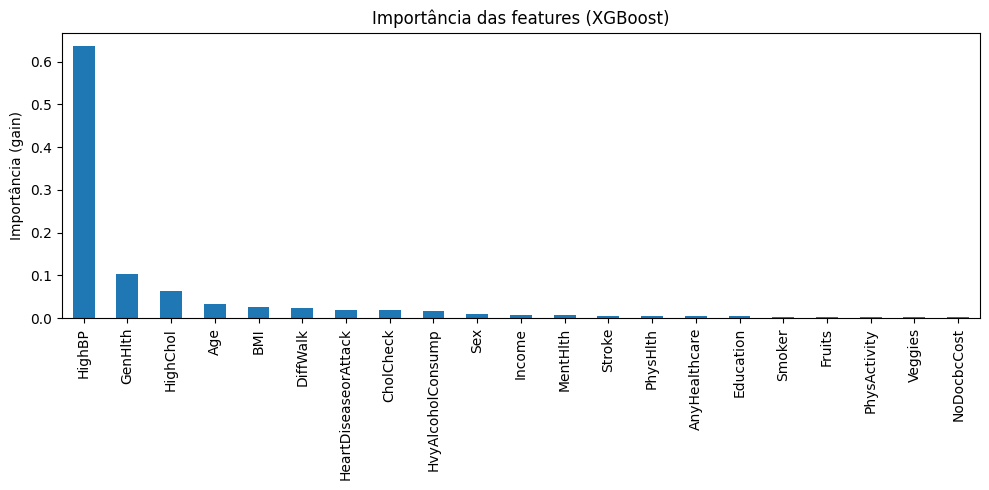

In [27]:
importancia = pd.Series(modelo_final.feature_importances_, index=FEATURES).sort_values(ascending=False)
print(importancia.head(5).round(3))

plt.figure(figsize=(10, 5))
importancia.plot(kind="bar")
plt.title("Importância das features (XGBoost)")
plt.ylabel("Importância (gain)")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "importancia_features.png", dpi=120)
plt.show()

As features mais relevantes são **HighBP, GenHlth, HighChol, Age e BMI**, fatores de risco clássicos de diabetes. O modelo aprendeu relações com sentido clínico e não ruído.

A importância por "gain" coloca HighBP muito à frente (0,64) porque ele tende a supervalorizar as variáveis usadas nas primeiras divisões das árvores. O SHAP, a seguir, distribui a importância de forma mais equilibrada; por isso as duas são reportadas.

## 10.2 SHAP: visão global e por paciente

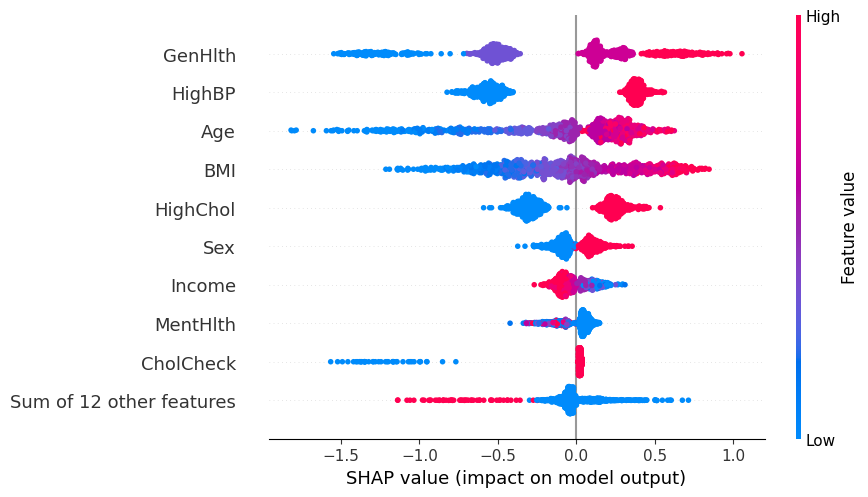

Paciente de maior risco — score 0.93


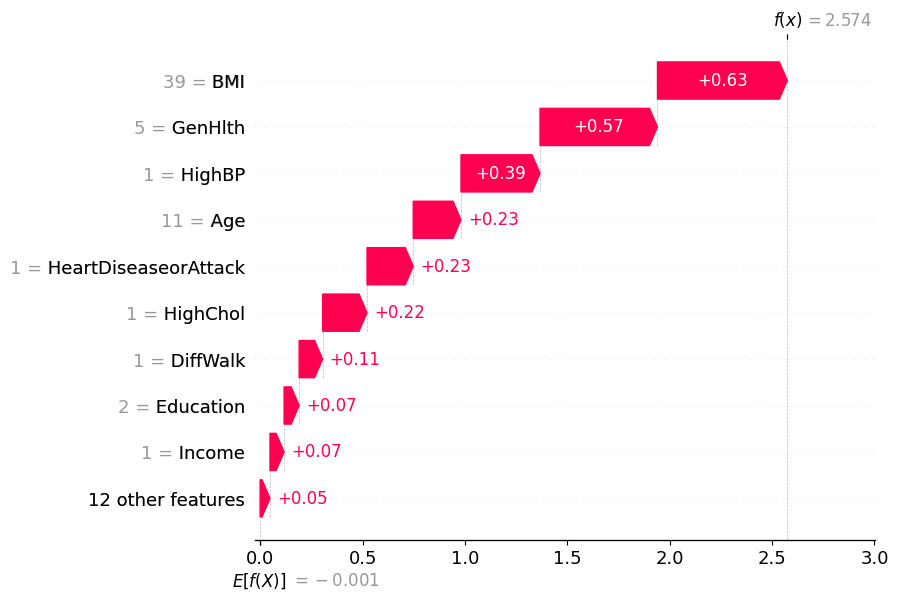

Paciente no limite da decisão — score 0.36


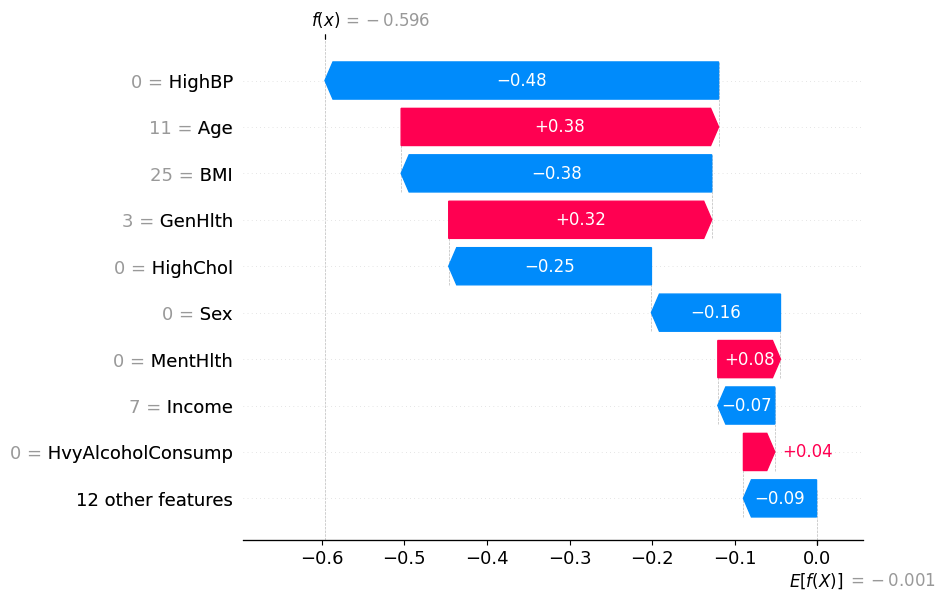

In [28]:
amostra = X_test.sample(1000, random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(modelo_final)
valores_shap = explainer(amostra)

# Visão global: beeswarm
shap.plots.beeswarm(valores_shap)

# Individual: o paciente de maior risco e o paciente mais próximo do limiar
proba_amostra = modelo_final.predict_proba(amostra)[:, 1]
i_alto = int(np.argmax(proba_amostra))
i_limiar = int(np.argmin(np.abs(proba_amostra - LIMIAR)))

for titulo, i in [("Paciente de maior risco", i_alto), ("Paciente no limite da decisão", i_limiar)]:
    print(f"{titulo} — score {proba_amostra[i]:.2f}")
    shap.plots.waterfall(valores_shap[i])

Foi usada uma amostra de 1.000 pacientes do teste (em vez dos 34 mil) porque o cálculo do SHAP é pesado — para a visualização, 1000 já é mais que suficiente.

## 10.3 Odds ratios da Regressão Logística

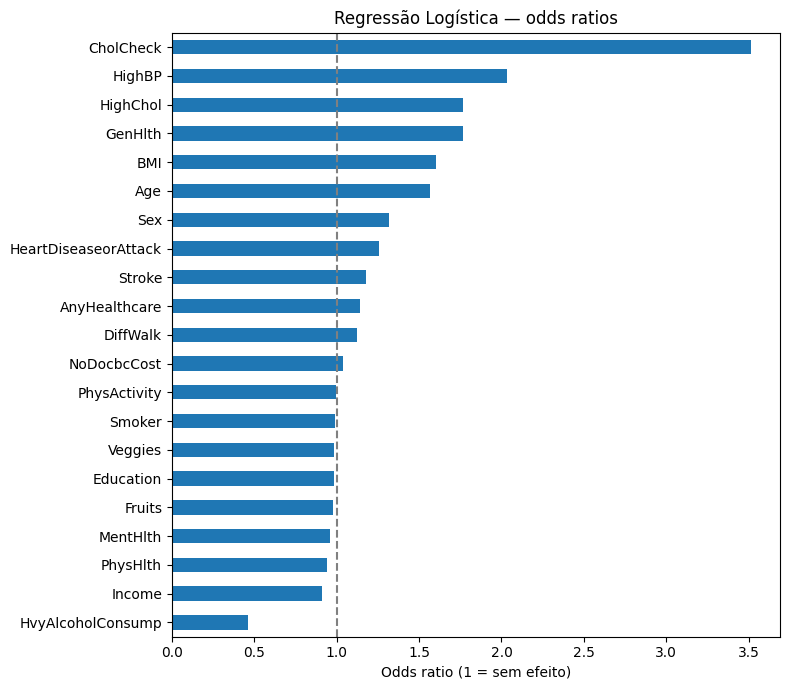

CholCheck    3.51
HighBP       2.03
HighChol     1.77
GenHlth      1.76
BMI          1.60
Age          1.56
dtype: float64

In [29]:
modelo_lr = modelos["Regressão Logística"]
nomes = [n.split("__")[1] for n in modelo_lr.named_steps["prep"].get_feature_names_out()]
odds_ratio = pd.Series(np.exp(modelo_lr.named_steps["modelo"].coef_[0]), index=nomes)
odds_ratio.sort_values().plot.barh(figsize=(8, 7))
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("Odds ratio (1 = sem efeito)")
plt.title("Regressão Logística — odds ratios")
plt.tight_layout()
plt.show()

odds_ratio.sort_values(ascending=False).round(2).head(6)

Odds ratio maior que 1 aumenta a chance de diabetes; menor que 1 diminui. Para as binárias, o valor compara ter contra não ter a condição; para contínuas e ordinais, que foram padronizadas, compara um desvio padrão a mais.

As interpretações do XGBoost (SHAP) e da Regressão Logística (odds ratios) concordam nos principais fatores: pressão alta, saúde geral autoavaliada, colesterol alto, IMC e idade, todos fatores de risco reconhecidos. A forte associação com CholCheck indica que o rótulo reflete também o acesso ao diagnóstico, uma limitação dos dados autorrelatados. Fazer exame de colesterol não causa diabetes: quem vai ao médico tem a chance de ser diagnosticado, e quem não vai continua aparecendo na base como "não diabético".

# 11. Desempenho por subgrupo

Uma média geral de 90% de recall pode esconder um grupo para o qual o modelo funciona pior. Em saúde, isso é uma questão de equidade.

In [30]:
resultado = X_test.assign(real=y_test.values, previsto=pred_teste)
resultado["Sexo"] = resultado["Sex"].map({0: "Feminino", 1: "Masculino"})
resultado["Faixa de renda"] = pd.cut(resultado["Income"], bins=[0, 3, 6, 8],
                                     labels=["Baixa (1–3)", "Média (4–6)", "Alta (7–8)"])

linhas = []
for coluna in ["Sexo", "Faixa de renda"]:
    for grupo, dados in resultado.groupby(coluna, observed=True):
        linhas.append({
            "Variável": coluna, "Grupo": grupo, "Pacientes": len(dados),
            "Prevalência": dados["real"].mean(),
            "Recall": recall_score(dados["real"], dados["previsto"]),
            "Precisão": precision_score(dados["real"], dados["previsto"]),
        })
pd.DataFrame(linhas).round(3)

,Variável,Grupo,Pacientes,Prevalência,Recall,Precisão
0,Sexo,Feminino,19294,0.142,0.888,0.263
1,Sexo,Masculino,15174,0.167,0.908,0.266
2,Faixa de renda,Baixa (1–3),5726,0.243,0.940,0.319
3,Faixa de renda,Média (4–6),11943,0.173,0.920,0.271
4,Faixa de renda,Alta (7–8),16799,0.107,0.839,0.225


Entre os sexos, a diferença de recall é pequena (88,8% no sexo feminino e 90,8% no masculino). Por renda, ela é relevante: o modelo encontra 94,0% dos diabéticos de renda baixa, mas só 83,9% dos de renda alta.

A explicação provável é que a renda entra no modelo como fator de risco (seção 3.1), então um diabético de renda alta se parece menos com o perfil típico.

# 12. Discussão crítica e conclusões

## O que o modelo faz
O classificador estima, a partir de 21 indicadores de saúde autorrelatados, o score de uma pessoa ser diabética. Foram comparados três modelos (Regressão Logística, Random Forest e XGBoost) contra um baseline. O XGBoost com hiperparâmetros ajustados foi escolhido (ROC-AUC 0,82), com limiar definido para recall de 90%.

## Como ele pode ser usado na prática
O modelo deve funcionar como **triagem**, nunca como diagnóstico:

1. O paciente responde a um questionário curto com as 21 perguntas, todas respondíveis sem exame.
2. O sistema calcula o score e, acima do limiar, sinaliza o prontuário.
3. O médico vê o alerta junto com a explicação SHAP do paciente.
4. O médico decide se pede glicemia de jejum ou hemoglobina glicada. **A palavra final é dele.**

Como as perguntas não exigem exame, a triagem tem custo quase nulo e pode alcançar quem nunca foi testado.

## Limitações
1. **Dados autorrelatados.** O diagnóstico é o que a pessoa declarou em entrevista telefônica (BRFSS/CDC, 2015), não um exame laboratorial. O acúmulo de respostas em 0 e 30 no PhysHlth mostra o efeito do autorrelato.
2. **Viés de acesso ao diagnóstico.** A forte associação com CholCheck indica que diabéticos sem acompanhamento médico aparecem como "não diabéticos". O modelo tende a falhar justamente em quem mais precisaria da triagem.
3. **Desempenho desigual por renda.** O recall é cerca de 10 pontos menor na renda alta do que na renda baixa.
4. **Corte transversal.** O modelo identifica quem já tem diagnóstico; ele não prevê quem vai desenvolver diabetes.
5. **Associação, não causalidade.** Pressão alta e colesterol alto são, em parte, consequências do diabetes.
6. **Probabilidades não calibradas.** Com o peso nas classes, o score serve para ordenar pacientes, mas não é uma probabilidade real.
7. **Mudança de prevalência.** A remoção das duplicatas elevou a prevalência de 13,9% para 15,3%, deixando a precisão levemente otimista.
8. **Generalização.** Os dados são da população adulta dos EUA; o uso em outro país exigiria validação com dados locais.

## Conclusão
O projeto percorre um pipeline completo de aprendizado de máquina, da exploração à interpretação. O empate entre três algoritmos e o ganho nulo do ajuste de hiperparâmetros mostram que o desempenho está limitado pela informação dos dados autorrelatados, e não pelo modelo. Ainda assim, o modelo tem utilidade real como apoio à triagem, desde que usado com supervisão médica.